In [2]:
import sys
from pathlib import Path

# Add src/ to path so we can reuse load_data.py functions
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from load_data import get_spark, load_ratings, load_movies, load_users

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

spark = get_spark()
spark.sparkContext.setLogLevel("WARN")

ratings_sdf = load_ratings(spark)
movies_sdf = load_movies(spark)
users_sdf = load_users(spark)

print("Ratings:", ratings_sdf.count())
print("Movies:", movies_sdf.count())
print("Users:", users_sdf.count())

Ratings: 1000209
Movies: 3883
Users: 6040


In [3]:
ratings = ratings_sdf.toPandas()
movies = movies_sdf.toPandas()
users = users_sdf.toPandas()

ratings.head()

C:\Users\Iqra\OneDrive\Desktop\Movie_Recomm_Engine\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\Iqra\OneDrive\Desktop\Movie_Recomm_Engine\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\Iqra\OneDrive\Desktop\Movie_Recomm_Engine\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,user_id,movie_id,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


C:\Users\Iqra\AppData\Local\Temp\ipykernel_21180\3739448912.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=ratings, x="rating", palette="viridis")


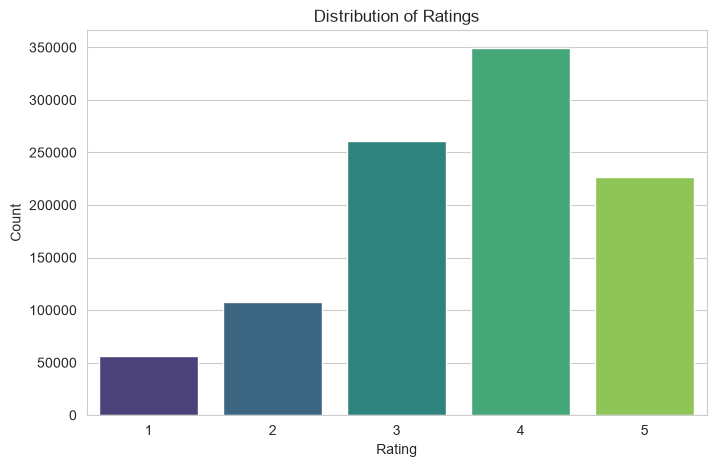

rating
1     5.62
2    10.75
3    26.11
4    34.89
5    22.63
Name: proportion, dtype: float64

In [4]:
plt.figure(figsize=(8, 5))
sns.countplot(data=ratings, x="rating", palette="viridis")
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

ratings["rating"].value_counts(normalize=True).sort_index().mul(100).round(2)


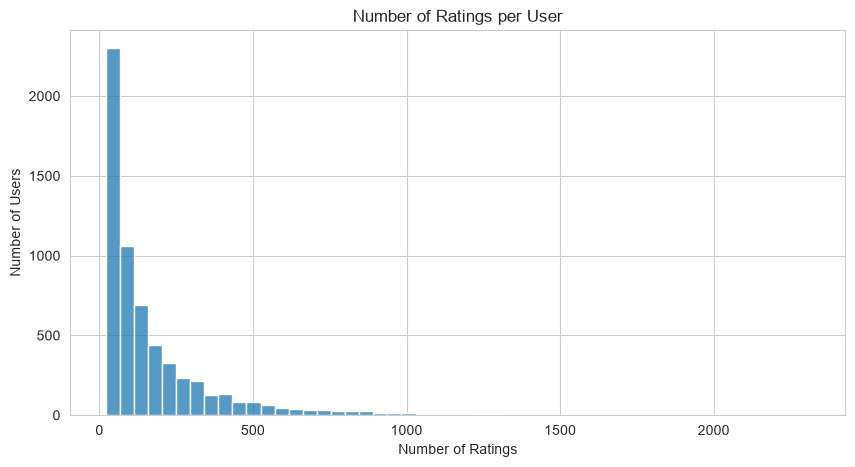

count    6040.000000
mean      165.597517
std       192.747029
min        20.000000
25%        44.000000
50%        96.000000
75%       208.000000
max      2314.000000
dtype: float64


In [5]:
ratings_per_user = ratings.groupby("user_id").size()

plt.figure(figsize=(10, 5))
sns.histplot(ratings_per_user, bins=50, kde=False)
plt.title("Number of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")
plt.show()

print(ratings_per_user.describe())

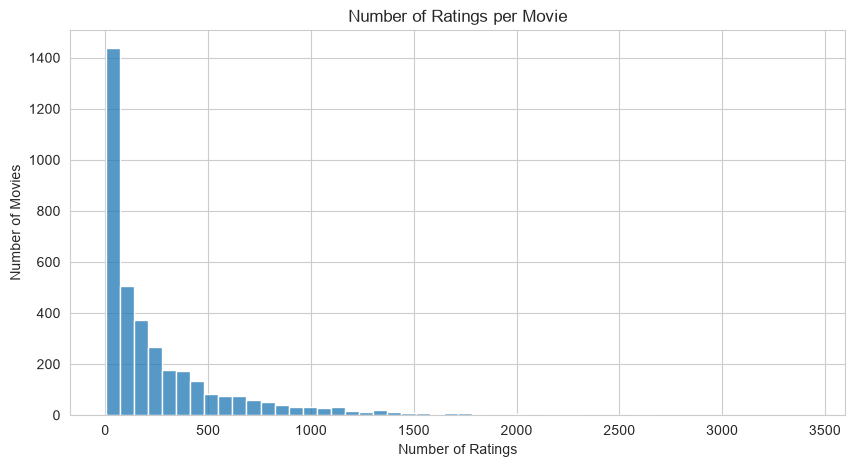

count    3706.000000
mean      269.889099
std       384.047838
min         1.000000
25%        33.000000
50%       123.500000
75%       350.000000
max      3428.000000
dtype: float64


,title,num_ratings
0,American Beauty (1999),3428
1,Star Wars: Episode IV - A New Hope (1977),2991
2,Star Wars: Episode V - The Empire Strikes Back...,2990
3,Star Wars: Episode VI - Return of the Jedi (1983),2883
4,Jurassic Park (1993),2672
5,Saving Private Ryan (1998),2653
6,Terminator 2: Judgment Day (1991),2649
7,"Matrix, The (1999)",2590
8,Back to the Future (1985),2583
9,"Silence of the Lambs, The (1991)",2578


In [6]:
ratings_per_movie = ratings.groupby("movie_id").size()

plt.figure(figsize=(10, 5))
sns.histplot(ratings_per_movie, bins=50, kde=False)
plt.title("Number of Ratings per Movie")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Movies")
plt.show()

print(ratings_per_movie.describe())

# Top 10 most-rated movies
top_movies = (
    ratings_per_movie.sort_values(ascending=False)
    .head(10)
    .rename("num_ratings")
    .reset_index()
    .merge(movies, on="movie_id")
    [["title", "num_ratings"]]
)
top_movies

Users with <=20 ratings: 86 out of 6040 (1.42%)
Movies with <=5 ratings: 329 out of 3706 (8.88%)


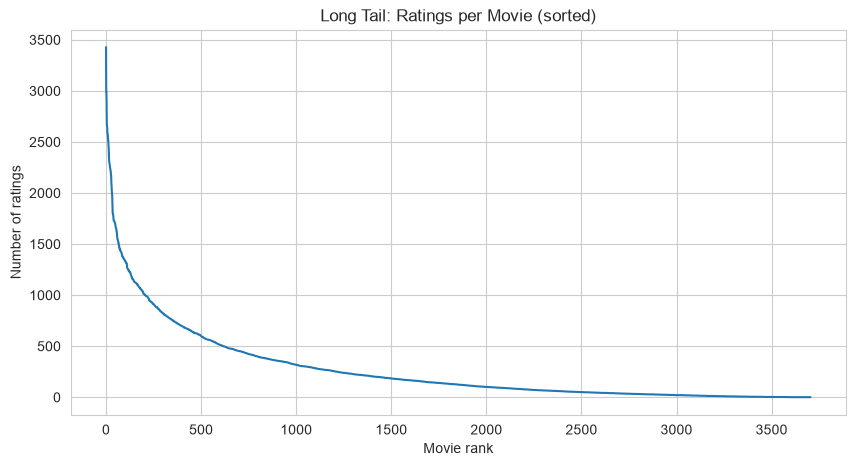

In [7]:
# Users with very few ratings (potential cold-start users)
cold_users = ratings_per_user[ratings_per_user <= 20]
print(f"Users with <=20 ratings: {len(cold_users)} out of {len(ratings_per_user)} "
      f"({len(cold_users)/len(ratings_per_user)*100:.2f}%)")

# Movies with very few ratings (potential cold-start / long-tail movies)
cold_movies = ratings_per_movie[ratings_per_movie <= 5]
print(f"Movies with <=5 ratings: {len(cold_movies)} out of {len(ratings_per_movie)} "
      f"({len(cold_movies)/len(ratings_per_movie)*100:.2f}%)")

# Visualize the long tail for movies
plt.figure(figsize=(10, 5))
ratings_per_movie.sort_values(ascending=False).reset_index(drop=True).plot()
plt.title("Long Tail: Ratings per Movie (sorted)")
plt.xlabel("Movie rank")
plt.ylabel("Number of ratings")
plt.show()